# Next Word Predictor using LSTM


## 1. Imports & config

In [1]:
import re, pickle, requests
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.model_selection import train_test_split

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

# ---- Hyperparameters ----
SEQ_LEN    = 10      # how many previous words the model sees
MAX_VOCAB  = 6000    # keep the most frequent words (rest -> <unk>)
EMBED_DIM  = 128
LSTM_UNITS = 256
BATCH_SIZE = 128
EPOCHS     = 40
SEED       = 42
tf.random.set_seed(SEED); np.random.seed(SEED)

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Load dataset
Default: *The Adventures of Sherlock Holmes* from Project Gutenberg. To use your own text, run the upload cell below instead.

In [2]:
URL = "https://www.gutenberg.org/cache/epub/1661/pg1661.txt"
raw = requests.get(URL, timeout=30).text

# strip Gutenberg header/footer
start = raw.find("*** START OF")
end   = raw.find("*** END OF")
if start != -1 and end != -1:
    raw = raw[raw.find("\n", start):end]

print("Characters:", len(raw))
print(raw[:500])

Characters: 574146





The Adventures of Sherlock Holmes

by Arthur Conan Doyle


Contents

   I.     A Scandal in Bohemia
   II.    The Red-Headed League
   III.   A Case of Identity
   IV.    The Boscombe Valley Mystery
   V.     The Five Orange Pips
   VI.    The Man with the Twisted Lip
   VII.   The Adventure of the Blue Carbuncle
   VIII.  The Adventure of the Speckled Band
   IX.    The Adventure of the Engineer’s Thumb
   X.     The Adventure of the Noble Bachelor
   XI.    The Advent


In [3]:
# OPTIONAL: use your own .txt file instead (uncomment and run)
# from google.colab import files
# uploaded = files.upload()
# raw = open(list(uploaded.keys())[0], encoding="utf-8").read()

## 3. Clean text

In [4]:
def clean_text(t):
    t = t.lower()
    t = t.replace("\r", " ").replace("\n", " ")
    t = re.sub(r"[“”]", '"', t)
    t = re.sub(r"[‘’]", "'", t)
    t = re.sub(r"[^a-z' ]+", " ", t)   # keep letters, apostrophes, spaces
    t = re.sub(r"\s+", " ", t).strip()
    return t

text = clean_text(raw)
print("Words:", len(text.split()))
print(text[:300])

Words: 105730
the adventures of sherlock holmes by arthur conan doyle contents i a scandal in bohemia ii the red headed league iii a case of identity iv the boscombe valley mystery v the five orange pips vi the man with the twisted lip vii the adventure of the blue carbuncle viii the adventure of the speckled ban


## 4. Tokenize & build sequences
Sliding window: every `SEQ_LEN` words predict the next one.

In [5]:
tokenizer = Tokenizer(num_words=MAX_VOCAB, oov_token="<unk>")
tokenizer.fit_on_texts([text])

VOCAB_SIZE = min(MAX_VOCAB, len(tokenizer.word_index) + 1)
index_word = {i: w for w, i in tokenizer.word_index.items() if i < VOCAB_SIZE}
print("Vocab size:", VOCAB_SIZE)

tokens = tokenizer.texts_to_sequences([text])[0]
print("Total tokens:", len(tokens))

sequences = np.array([tokens[i:i + SEQ_LEN + 1] for i in range(len(tokens) - SEQ_LEN)])
X, y = sequences[:, :-1], sequences[:, -1]
print("X:", X.shape, "y:", y.shape)

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.1, random_state=SEED)
print("Train:", X_train.shape, "Val:", X_val.shape)

Vocab size: 6000
Total tokens: 105730
X: (105720, 10) y: (105720,)
Train: (95148, 10) Val: (10572, 10)


## 5. Build the model
`sparse_categorical_crossentropy` lets us use integer labels, so no huge one-hot matrix.

In [6]:
model = Sequential([
    Embedding(VOCAB_SIZE, EMBED_DIM, input_length=SEQ_LEN),
    LSTM(LSTM_UNITS, return_sequences=True),
    Dropout(0.3),
    LSTM(LSTM_UNITS),
    Dropout(0.3),
    Dense(256, activation="relu"),
    Dense(VOCAB_SIZE, activation="softmax"),
])

model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer=tf.keras.optimizers.Adam(1e-3),
    metrics=["accuracy"],
)
model.build(input_shape=(None, SEQ_LEN))
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 10, 128)        │       768,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 10, 256)        │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 10, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 256)            │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6000)           │     1,542,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,295,344 (12.57 MB)

 Trainable params: 3,295,344 (12.57 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Train

In [7]:
callbacks = [
    EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    ModelCheckpoint("best_next_word_lstm.keras", monitor="val_loss", save_best_only=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, verbose=1),
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
)

Epoch 1/40
744/744 ━━━━━━━━━━━━━━━━━━━━ 15s 12ms/step - accuracy: 0.0596 - loss: 6.3113 - val_accuracy: 0.0750 - val_loss: 6.0708 - learning_rate: 0.0010
Epoch 2/40
744/744 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.0790 - loss: 5.8295 - val_accuracy: 0.0900 - val_loss: 5.9194 - learning_rate: 0.0010
Epoch 3/40
744/744 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.0972 - loss: 5.5405 - val_accuracy: 0.1057 - val_loss: 5.8707 - learning_rate: 0.0010
Epoch 4/40
744/744 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.1116 - loss: 5.3354 - val_accuracy: 0.1130 - val_loss: 5.8330 - learning_rate: 0.0010
Epoch 5/40
744/744 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.1209 - loss: 5.1752 - val_accuracy: 0.1177 - val_loss: 5.7859 - learning_rate: 0.0010
Epoch 6/40
744/744 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.1283 - loss: 5.0411 - val_accuracy: 0.1217 - val_loss: 5.8189 - learning_rate: 0.0010
Epoch 7/40
741/744 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.1311 - loss: 4

## 7. Training curves

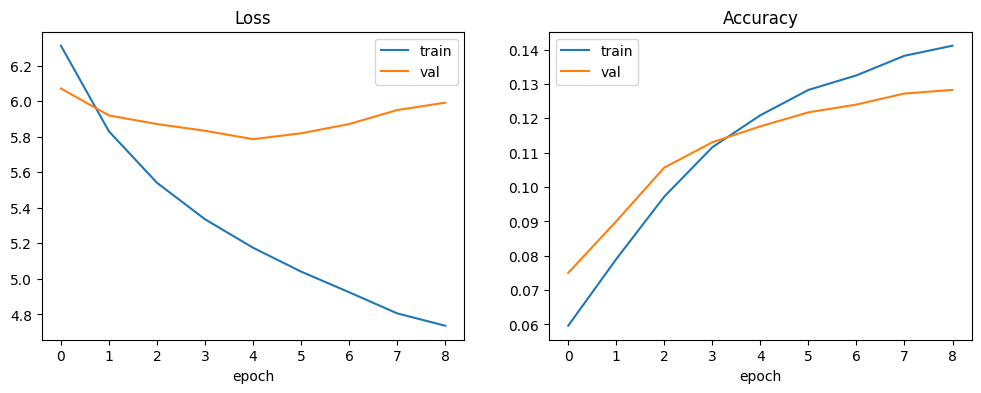

Val loss: 5.786 | Val acc: 0.118 | Perplexity: 325.7


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["loss"], label="train")
ax[0].plot(history.history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()

ax[1].plot(history.history["accuracy"], label="train")
ax[1].plot(history.history["val_accuracy"], label="val")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.show()

val_loss, val_acc = model.evaluate(X_val, y_val, verbose=0)
print(f"Val loss: {val_loss:.3f} | Val acc: {val_acc:.3f} | Perplexity: {np.exp(val_loss):.1f}")

## 8. Predict the next word (top-k)

In [9]:
unk_id = tokenizer.word_index["<unk>"]

def encode(seed):
    seq = tokenizer.texts_to_sequences([clean_text(seed)])[0]
    return pad_sequences([seq[-SEQ_LEN:]], maxlen=SEQ_LEN, padding="pre")

def predict_next_words(seed, k=5):
    probs = model.predict(encode(seed), verbose=0)[0].copy()
    probs[0] = 0            # padding
    probs[unk_id] = 0       # never suggest <unk>
    probs /= probs.sum()
    top = probs.argsort()[-k:][::-1]
    return [(index_word[i], round(float(probs[i]), 4)) for i in top]

for s in ["i have no doubt that", "holmes took his", "it was a"]:
    print(f"'{s}' ->", predict_next_words(s))

'i have no doubt that' -> [('i', 0.1934), ('he', 0.0987), ('you', 0.059), ('it', 0.0548), ('the', 0.0518)]
'holmes took his' -> [('eyes', 0.0198), ('little', 0.013), ('head', 0.0115), ('simon', 0.0112), ('own', 0.0107)]
'it was a' -> [('little', 0.0154), ('matter', 0.0094), ('man', 0.0093), ('other', 0.0074), ('room', 0.0066)]


## 9. Generate text (temperature sampling)
Lower temperature = safer/repetitive, higher = more creative/random.

In [10]:
def sample(probs, temperature=0.8):
    probs = np.asarray(probs, dtype="float64")
    probs[0] = 0; probs[unk_id] = 0
    probs = np.log(probs + 1e-9) / temperature
    probs = np.exp(probs)
    probs /= probs.sum()
    return np.random.choice(len(probs), p=probs)

def generate_text(seed, n_words=30, temperature=0.8):
    out = clean_text(seed)
    for _ in range(n_words):
        probs = model.predict(encode(out), verbose=0)[0]
        out += " " + index_word[sample(probs, temperature)]
    return out

print(generate_text("sherlock holmes was", n_words=30, temperature=0.7))

sherlock holmes was a bedrooms we am a door and together in a very morocco she was a matter to a strange time of the long hand in a hand of of the


## 10. Interactive predictor

In [11]:
while True:
    s = input("Type a phrase (or 'q' to quit): ")
    if s.strip().lower() == "q":
        break
    if not s.strip():
        continue
    print("Suggestions:", [w for w, p in predict_next_words(s, k=5)], "\n")

Type a phrase (or 'q' to quit): sherlock
Suggestions: ['holmes', 'he', 'i', 'to', 'she'] 

Type a phrase (or 'q' to quit): detective
Suggestions: ['the', 'a', 'it', 'i', 'you'] 

Type a phrase (or 'q' to quit): holmes
Suggestions: ['is', 'was', 'i', 'had', 'and'] 

Type a phrase (or 'q' to quit): q
